# Buổi F6: Phát hiện bất thường, tìm giao dịch lạ khi chưa ai chỉ ra giao dịch xấu

**Hiện trường.** Mỗi ngày cửa hàng của chị Hạnh có hàng nghìn giao dịch. Một số giao dịch **lạ**: nhập sai số tiền, thẻ bị lấy trộm, nhân viên bấm nhầm. Không ai ghi sẵn "giao dịch này xấu", và chị không có thời gian xem hết. Chị cần một danh sách ngắn **những giao dịch đáng xem nhất**.

Buổi này dạy **phát hiện bất thường** (*anomaly detection*): học xem "bình thường" trông thế nào, rồi chấm điểm mức **lạ** cho từng điểm. Ta thử ba cách: luật thống kê đơn giản, **Isolation Forest** (rừng cô lập), và **LOF** (hệ số ngoại lai cục bộ).

**Ẩn dụ:** trong lớp đông, ai ngồi một mình xa cả lớp thì dễ nhận ra. Isolation Forest hỏi "cần chia lớp bằng bao nhiêu đường kẻ ngẫu nhiên để tách riêng người này ra?": người lạ chỉ cần vài đường. LOF hỏi "người này có ngồi thưa hơn hẳn những người xung quanh họ không?".

**Mindset của người làm dữ liệu:** bất thường **không phải là xấu**, chỉ là **hiếm và khác**. Kết quả là danh sách để người xem, không phải bản án.

**Lưu ý:** dữ liệu giao dịch dựng có chủ đích (ta cài sẵn 30 giao dịch lạ để có đáp án chấm); ngoài đời thường không có đáp án như vậy.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: máy chỉ ra giao dịch lạ |
| Chặng 1 | Vì sao điểm lạ dễ bị cô lập: đếm số lần chia |
| Chặng 2 | Ba cách so với nhau, chấm bằng đáp án cài sẵn |
| Chặng 3 | Ngưỡng và ngân sách xem: xem 20 hay 100 giao dịch |
| Chặng 4 | Bẫy: mật độ khác nhau và thang đo |
| Chặng 5 | Khi không có đáp án: xem tay và nói được lý do |

## Chặng 0: Thấy ngay, giao dịch lạ

**Câu hỏi:** trong 1.000 giao dịch, máy chỉ ra 30 giao dịch lạ nhất, có trúng không?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

flagged: 30 | of which truly planted: 30 | planted total: 30


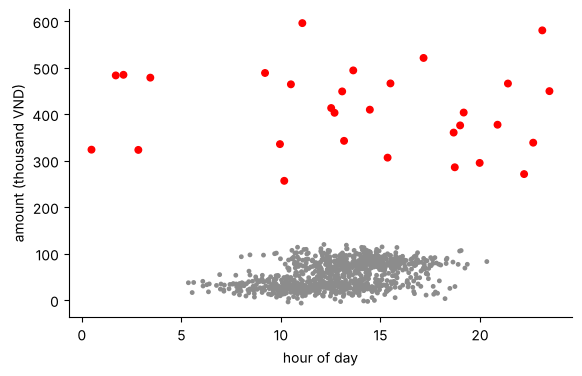

In [2]:
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
rng = np.random.RandomState(0)
normal, _ = make_blobs(n_samples=970, centers=[[12, 30], [14, 80]], cluster_std=[[2.5, 12], [2.0, 15]], random_state=0)
odd = np.column_stack([rng.uniform(0, 24, 30), rng.uniform(250, 600, 30)])
X = np.vstack([normal, odd]); is_odd = np.array([0] * 970 + [1] * 30)
df = pd.DataFrame(X, columns=["hour", "amount_thousand_vnd"])
iso = IsolationForest(n_estimators=300, contamination=0.03, random_state=0).fit(X)
df["flag"] = iso.predict(X) == -1
df["score"] = -iso.score_samples(X)
hit = int((df["flag"] & (is_odd == 1)).sum())
print("flagged:", int(df["flag"].sum()), "| of which truly planted:", hit, "| planted total:", int(is_odd.sum()))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(df["hour"], df["amount_thousand_vnd"], c=np.where(df["flag"], "red", GRAY), s=np.where(df["flag"], 22, 6))
ax.set_xlabel("hour of day"); ax.set_ylabel("amount (thousand VND)")
plt.show()

**Giải thích từng dòng**

- `make_blobs(..., centers=[[12, 30], [14, 80]], ...)`: giao dịch bình thường: hai nhóm (buổi sáng và buổi chiều), số tiền từ vài chục đến vài trăm nghìn. Dựng có chủ đích.
- `rng.uniform(250, 600, 30)`: cài 30 giao dịch có số tiền rất lớn ở giờ ngẫu nhiên. `is_odd` là đáp án chỉ để chấm.
- `IsolationForest(n_estimators=300, contamination=0.03)`: rừng 300 cây cô lập. `contamination` là tỷ lệ ta **dự đoán** là bất thường (3%); nó đặt ngưỡng cắt.
- `iso.predict(X) == -1`: sklearn dùng nhãn `-1` cho bất thường và `1` cho bình thường.
- `-iso.score_samples(X)`: điểm lạ: **càng cao càng lạ** (sklearn trả điểm âm nên ta đổi dấu).

**Cách đọc.**
- **Con số:** máy gắn cờ **30** giao dịch, trong đó **30** thật sự là giao dịch cài sẵn, trên tổng **30**. Lưu ý: ta đặt `contamination=0.03` đúng bằng tỷ lệ tự cài, nên kết quả đẹp; ngoài đời không biết trước tỷ lệ này (chặng 3 bàn cách chọn ngưỡng).
- **Bức tranh:** các điểm đỏ nằm ở vùng số tiền lớn, xa hai đám bình thường. Máy chưa hề biết "số tiền lớn là xấu": nó chỉ thấy chúng **hiếm và khác**.
- **Câu hỏi tiếp:** vì sao một điểm lạ lại dễ bị phát hiện đến thế?

**Mang về chặng 1:** phát hiện bất thường = học "bình thường", chấm điểm độ lạ cho từng điểm.

## Chặng 1: Vì sao điểm lạ dễ bị cô lập

**Câu hỏi:** cần bao nhiêu nhát chia ngẫu nhiên để tách riêng một điểm?

In [3]:
def split_count(points, idx, rng, limit=40):
    mask = np.ones(len(points), dtype=bool)
    n = 0
    while mask.sum() > 1 and n < limit:
        col = rng.randint(points.shape[1])
        lo, hi = points[mask, col].min(), points[mask, col].max()
        if lo == hi:
            break
        cut = rng.uniform(lo, hi)
        side = points[:, col] < cut
        mask &= (side == side[idx])
        n += 1
    return n

rng2 = np.random.RandomState(1)
repeat = 200
avg_splits = np.array([np.mean([split_count(X, i, rng2) for _ in range(repeat)]) for i in range(0, len(X), 5)])
sub_odd = is_odd[::5]
print("average random splits to isolate a point -> normal:", round(avg_splits[sub_odd == 0].mean(), 1), "| planted odd:", round(avg_splits[sub_odd == 1].mean(), 1))

average random splits to isolate a point -> normal: 16.4 | planted odd: 7.5


**Giải thích từng dòng**

- `rng.randint(points.shape[1])`: chọn ngẫu nhiên một cột (giờ hoặc số tiền).
- `rng.uniform(lo, hi)`: chọn ngẫu nhiên một ngưỡng cắt giữa giá trị nhỏ nhất và lớn nhất của những điểm còn lại.
- `mask &= (side == side[idx])`: chỉ giữ lại những điểm cùng phía với điểm đang xét. Lặp đến khi điểm đó đứng một mình.
- `np.mean([... for _ in range(repeat)])`: lặp 200 lần lấy trung bình số nhát cắt, vì mỗi lần cắt ngẫu nhiên một khác.

**Cách đọc.**
- **Con số:** trung bình cần **16,4** nhát cắt để cô lập một giao dịch bình thường, nhưng chỉ **7,5** nhát với giao dịch lạ.
- **Bức tranh:** giao dịch lạ đứng một mình ở vùng trống nên một vài nhát cắt đã tách được; giao dịch bình thường nằm giữa đám đông nên phải cắt nhiều. Isolation Forest làm đúng việc này với cả rừng cây ngẫu nhiên rồi lấy trung bình độ sâu: **ít nhát cắt = điểm lạ cao**.
- **Câu hỏi tiếp:** ngoài cách này còn cách nào? Cách nào tốt hơn?

**Mang về chặng 2:** điểm lạ dễ cô lập; số nhát cắt trung bình chính là thước đo độ lạ.

## Chặng 2: Ba cách so với nhau

**Câu hỏi:** luật đơn giản, Isolation Forest và LOF, cách nào xếp giao dịch lạ lên đầu tốt nhất?

In [4]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
Z = StandardScaler().fit_transform(X)
score_z = np.abs(Z).max(axis=1)
score_iso = -IsolationForest(n_estimators=300, random_state=0).fit(Z).score_samples(Z)
score_lof = -LocalOutlierFactor(n_neighbors=30).fit(Z).negative_outlier_factor_
comp = pd.DataFrame({name: {"ROC AUC": roc_auc_score(is_odd, s), "average precision": average_precision_score(is_odd, s), "found in top 30": int(is_odd[np.argsort(-s)[:30]].sum())} for name, s in [("max |z-score|", score_z), ("Isolation Forest", score_iso), ("LOF", score_lof)]}).round(3)
print(comp.to_string())

                   max |z-score|  Isolation Forest     LOF
ROC AUC                    1.000               1.0   0.998
average precision          0.999               1.0   0.944
found in top 30           29.000              30.0  25.000


**Giải thích từng dòng**

- `np.abs(Z).max(axis=1)`: luật đơn giản: giao dịch càng lệch xa trung bình ở **một** cột nào đó (tính theo độ lệch chuẩn) thì càng lạ.
- `IsolationForest(...).fit(Z).score_samples(Z)`: điểm lạ từ rừng cô lập (chặng 0 và 1).
- `LocalOutlierFactor(n_neighbors=30)`: LOF so mật độ quanh mỗi điểm với mật độ quanh hàng xóm của nó: ai thưa hơn hẳn hàng xóm thì lạ.
- `negative_outlier_factor_`: điểm LOF của sklearn là số âm; đổi dấu để "cao là lạ".
- `roc_auc_score(is_odd, s)`: xác suất một giao dịch lạ thật được chấm điểm cao hơn một giao dịch bình thường (1 là hoàn hảo, 0,5 là ngẫu nhiên).
- `average_precision_score`: trung bình độ chính xác khi duyệt từ điểm cao xuống; nhạy hơn ROC khi bất thường hiếm.
- `is_odd[np.argsort(-s)[:30]].sum()`: trong 30 giao dịch điểm cao nhất, bao nhiêu thật sự là giao dịch cài sẵn.

**Cách đọc.**
- **Con số:** số giao dịch lạ thật nằm trong 30 điểm cao nhất: z-score **29**, Isolation Forest **30**, LOF **25**. ROC AUC lần lượt **1,000**, **1,000**, **0,998**.
- **Bức tranh:** ở bài này giao dịch lạ lệch mạnh theo **một** cột (số tiền), nên ngay cả luật z-score đơn giản cũng làm tốt. Đừng vội dùng thuật toán phức tạp khi một luật rẻ đã đủ: **luôn thử luật đơn giản làm mốc**, như mô hình "đoán số đông" ở C1.
- **Quy tắc đọc:** thuật toán phức tạp chỉ đáng khi bất thường nằm ở **tổ hợp** các cột (ví dụ số tiền bình thường, giờ bình thường, nhưng tổ hợp lại hiếm). Chặng 4 cho một ví dụ.
- **Câu hỏi tiếp:** danh sách bao nhiêu giao dịch thì đủ?

**Mang về chặng 3:** luôn có một luật đơn giản làm mốc so sánh.

## Chặng 3: Ngưỡng và ngân sách xem

**Câu hỏi:** nhân viên chỉ xem được 20 giao dịch mỗi ngày, hay 100, thì chọn ngưỡng nào?

In [5]:
order = np.argsort(-score_iso)
rows = []
for budget in [10, 20, 30, 50, 100, 200]:
    caught = int(is_odd[order[:budget]].sum())
    rows.append({"transactions reviewed": budget, "odd found": caught, "precision": round(caught / budget, 3), "recall": round(caught / is_odd.sum(), 3)})
budget_table = pd.DataFrame(rows).set_index("transactions reviewed")
print(budget_table.to_string())

                       odd found  precision  recall
transactions reviewed                              
10                            10       1.00   0.333
20                            20       1.00   0.667
30                            30       1.00   1.000
50                            30       0.60   1.000
100                           30       0.30   1.000
200                           30       0.15   1.000


**Giải thích từng dòng**

- `np.argsort(-score_iso)`: xếp giao dịch từ lạ nhất xuống ít lạ nhất.
- `order[:budget]`: chỉ xem `budget` giao dịch đầu danh sách.
- `caught / budget`: **precision**: trong số xem, bao nhiêu thật sự lạ (không phí công).
- `caught / is_odd.sum()`: **recall**: trong số giao dịch lạ có thật, bắt được bao nhiêu (không bỏ sót).

**Cách đọc.**
- **Con số:** xem **20** giao dịch thì bắt **20** giao dịch lạ (độ chính xác **100%**, bỏ sót **33%**); xem **100** thì bắt **30** (độ chính xác **30%**).
- **Bức tranh:** đây là cùng đánh đổi precision và recall của C3, D5: xem nhiều thì ít bỏ sót nhưng tốn công. Với bất thường, ngưỡng thực chất là **ngân sách xem của con người**, không phải con số `contamination` chọn trước.
- **Quy tắc đọc:** hỏi trước "nhân viên xem được bao nhiêu mỗi ngày, và bỏ sót một giao dịch lạ đắt hay xem thừa một giao dịch đắt hơn?" rồi mới chọn ngưỡng.
- **Câu hỏi tiếp:** điều gì làm các cách này sai?

**Mang về chặng 4:** chọn số giao dịch xem theo ngân sách, đọc cả precision lẫn recall.

## Chặng 4: Bẫy, mật độ khác nhau và tổ hợp lạ

**Câu hỏi:** có kiểu bất thường mà luật z-score không thấy không?

In [6]:
a, _ = make_blobs(300, centers=[[0, 0]], cluster_std=0.4, random_state=0)
b, _ = make_blobs(300, centers=[[8, 0]], cluster_std=2.0, random_state=1)
local_odd = np.array([[1.6, 0.0], [0.0, 1.7], [-1.5, -0.4], [1.2, 1.2]])
T = np.vstack([a, b, local_odd]); t_odd = np.array([0] * 600 + [1] * 4)
Tz = StandardScaler().fit_transform(T)
res = {}
for name, s in [("max |z-score|", np.abs(Tz).max(axis=1)),
                ("Isolation Forest", -IsolationForest(n_estimators=300, random_state=0).fit(Tz).score_samples(Tz)),
                ("LOF", -LocalOutlierFactor(n_neighbors=30).fit(Tz).negative_outlier_factor_)]:
    rank = (-s).argsort().argsort()
    res[name] = {"rank of planted odd (best to worst)": sorted((rank[600:] + 1).tolist()), "found in top 10": int(t_odd[np.argsort(-s)[:10]].sum())}
print(pd.DataFrame(res).T.to_string())

                 rank of planted odd (best to worst) found in top 10
max |z-score|                   [152, 210, 552, 588]               0
Isolation Forest                   [43, 45, 48, 137]               0
LOF                                     [2, 3, 4, 5]               4


**Giải thích từng dòng**

- `cluster_std=0.4 / 2.0`: một nhóm khách rất đều (bán đồng giá), một nhóm rất tản (bán đủ loại). Hai nhóm có mật độ rất khác nhau.
- `local_odd = [[1.6, 0.0], ...]`: 4 giao dịch cài vào **ngay sát** nhóm đều, cách tâm khoảng 1,5: với nhóm tản thì chẳng là gì, nhưng với nhóm đều thì rất lạ.
- `rank = (-s).argsort().argsort()`: thứ hạng độ lạ của mỗi điểm (1 là lạ nhất).

**Cách đọc.**
- **Con số:** thứ hạng độ lạ của 4 giao dịch cài sẵn (1 là lạ nhất trong 604): z-score **[152, 210, 552, 588]**, Isolation Forest **[43, 45, 48, 137]**, LOF **[2, 3, 4, 5]**.
- **Bức tranh:** bất thường **cục bộ** là điểm chỉ lạ so với hàng xóm của nó. Luật toàn cục (z-score) bỏ qua vì so với cả đám đông thì chúng chẳng xa. LOF được thiết kế để so với hàng xóm nên nhìn thấy chúng rõ hơn; Isolation Forest nằm ở giữa.
- **Quy tắc đọc:** bất thường **toàn cục** (xa mọi người): luật đơn giản hoặc Isolation Forest. Bất thường **cục bộ** (lạ so với nhóm của nó): LOF. Nếu không chắc, chạy cả hai rồi xem điểm chung.
- **Lưu ý:** LOF mặc định không có `predict` cho dữ liệu mới. Cần chấm dữ liệu mới thì tạo với `LocalOutlierFactor(novelty=True)` và học chỉ trên dữ liệu bình thường.

**Mang về chặng 5:** chọn cách theo kiểu bất thường cần tìm: toàn cục hay cục bộ.

## Chặng 5: Khi không có đáp án, xem tay và nói được lý do

**Câu hỏi:** ngoài đời không có `is_odd`. Làm sao biết danh sách có ích?

In [7]:
top = df.assign(score=score_iso).sort_values("score", ascending=False).head(8).copy()
profile = df[["hour", "amount_thousand_vnd"]].describe().loc[["25%", "50%", "75%", "max"]].round(0)
top["amount vs median (x)"] = (top["amount_thousand_vnd"] / df["amount_thousand_vnd"].median()).round(1)
print(top[["hour", "amount_thousand_vnd", "amount vs median (x)", "score"]].round(2).to_string())
print()
print(profile.to_string())

      hour  amount_thousand_vnd  amount vs median (x)  score
978  23.13               580.31                  10.4   0.81
984   1.70               483.37                   8.7   0.79
985   2.09               484.72                   8.7   0.79
986   0.49               323.63                   5.8   0.78
996   3.44               478.59                   8.6   0.78
990  23.49               449.57                   8.1   0.77
994   2.84               323.11                   5.8   0.76
997  22.67               338.65                   6.1   0.76

     hour  amount_thousand_vnd
25%  11.0                 30.0
50%  13.0                 56.0
75%  15.0                 82.0
max  23.0                596.0


**Giải thích từng dòng**

- `.sort_values("score", ascending=False).head(8)`: lấy 8 giao dịch lạ nhất để người xem đọc từng dòng.
- `top["amount_thousand_vnd"] / df[...].median()`: đổi sang "gấp bao nhiêu lần mức giữa": con người đọc câu "gấp 5 lần" dễ hơn đọc một điểm số.
- `df[[...]].describe().loc[[...]]`: bảng so sánh: mức bình thường (tứ phân vị) và mức lớn nhất.

**Cách đọc.**
- **Con số:** 8 giao dịch lạ nhất có số tiền gấp từ **5,8** đến **10,4** lần mức giữa.
- **Bức tranh:** một danh sách hữu ích có hai phần: **thứ tự** (xem ai trước) và **lý do đọc được** (vì sao lạ: "gấp mấy lần bình thường", "giờ hiếm"). Điểm số trần không giúp ai quyết định.
- **Cách kiểm khi không có đáp án:** (1) cho nhân viên xem 20 giao dịch đầu và đếm bao nhiêu thật đáng xem; (2) chạy lại bằng hai cách khác nhau và xem danh sách chung; (3) theo dõi theo tuần: danh sách có ổn định hay nhảy loạn.
- **Lưu ý:** bất thường không phải gian lận. Mỗi giao dịch lạ có thể là khách mua hàng lớn hợp lệ. Danh sách chỉ nói **nên xem**.

**Mang về:** chấm điểm lạ → xếp thứ tự → kèm lý do đọc được → để người quyết định.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Phát hiện bất thường = học bình thường, chấm điểm độ lạ; không cần nhãn. |
| 1 | Điểm lạ cần ít nhát cắt ngẫu nhiên để cô lập; đó là Isolation Forest. |
| 2 | Luôn có luật đơn giản làm mốc; thuật toán phức tạp phải hơn mốc. |
| 3 | Ngưỡng là ngân sách xem của con người; đọc cả precision và recall. |
| 4 | Bất thường toàn cục dùng luật hoặc Isolation Forest; cục bộ dùng LOF. |
| 5 | Kèm lý do đọc được, kiểm bằng xem tay; danh sách chỉ nói nên xem. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Người ngồi một mình xa cả lớp | điểm bất thường | nhãn `-1` |
| Cần mấy đường kẻ để tách riêng một người | độ dài đường cô lập | `IsolationForest` |
| Ngồi thưa hơn hẳn người xung quanh | hệ số ngoại lai cục bộ | `LocalOutlierFactor` |
| Tỷ lệ giao dịch dự đoán là lạ | tỷ lệ nhiễm | `contamination` |
| Điểm lạ càng cao càng đáng xem | điểm bất thường | `score_samples` |
| Xem 20 giao dịch thì bắt được mấy | precision, recall tại k | `argsort`, `[:k]` |

**Thử thách tự làm**

1. Ở chặng 0, đổi `contamination` thành 0,01 và 0,10. Số giao dịch bị gắn cờ và số bắt trúng thay đổi thế nào?
2. Ở chặng 2, cài thêm 30 giao dịch lạ kiểu **tổ hợp**: giờ 3 giờ sáng nhưng số tiền bình thường. Cách nào bắt được?
3. Ở chặng 4, tạo `LocalOutlierFactor(novelty=True)` học trên 600 điểm bình thường rồi chấm 4 điểm cài sẵn bằng `score_samples`.
4. Chạy chặng 3 với `n_estimators` 10, 100, 1000. Danh sách top 30 có ổn định không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích Isolation Forest bằng ví dụ người ngồi một mình.
- [ ] Dùng luật đơn giản làm mốc so sánh.
- [ ] Chọn ngưỡng theo ngân sách xem, đọc precision và recall.
- [ ] Phân biệt bất thường toàn cục và cục bộ.
- [ ] Đưa ra danh sách kèm lý do, không chỉ điểm số.

## Phần thưởng (Tip pro): Sang Phần G: mạng nơ-ron và các chủ đề nâng cao


Phần F kết thúc ở đây: gom nhóm (F1 đến F3), nén và nhìn (F4, F5), bất thường (F6), tất cả **không cần nhãn**. Phần G bước vào những chủ đề nâng cao hơn, bắt đầu từ mạng nơ-ron.